# Time Analysis and Statistical Summary

**Project:** Early Prediction of Late Delivery Risk in Brazilian E-Commerce

## 1. Data Loading and Validation

This notebook analyzes monthly late-delivery patterns
using the order-level research dataset prepared
during the data preprocessing stage.

The analysis focuses on:
- Monthly order volume.
- Monthly late-delivery rates.
- Data completeness and observation coverage.
- Statistical uncertainty and limitations.
- Consolidation of the group's statistical findings.

In [1]:
# =========================================================
# SECTION 1: DATA LOADING AND VALIDATION
# =========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
ROOT = Path.cwd()

if not (ROOT / "data" / "processed" / "research_data.csv").exists():
    ROOT = ROOT.parent

# Load research dataset
data_path = ROOT / "data" / "processed" / "research_data.csv"

df = pd.read_csv(
    data_path,
    dtype={
        "order_id": "string",
        "purchase_month": "string"
    },
    parse_dates=["order_purchase_timestamp"]
)

# Basic validation
print("Total rows:", len(df))
print("Unique orders:", df["order_id"].nunique())
print("Total columns:", len(df.columns))

print("\nLate delivery labels:")
print(df["is_late"].value_counts(dropna=False))

print("\nTime range:")
print(
    df["purchase_month"].min(),
    "to",
    df["purchase_month"].max()
)

# Ensure one row per order
assert df["order_id"].is_unique, "Duplicate order_id detected!"

print("\nData validation passed.")

Total rows: 99441
Unique orders: 99441
Total columns: 28

Late delivery labels:
is_late
0.0    89936
1.0     6534
NaN     2971
Name: count, dtype: int64

Time range:
2016-09 to 2018-10

Data validation passed.


## 2. Monthly Late Delivery Analysis

### Objective
Analyze how order volume and late-delivery rates change
across purchase months.

### Methodology
- Include only orders with valid `is_late` labels (0 or 1).
- Group orders by `purchase_month`.
- Calculate the number of eligible orders and late orders.
- Calculate the monthly late-delivery rate as a percentage.
- Exclude unlabeled orders from the denominator.

### Formula
Late Delivery Rate (%) = (Late Orders / Eligible Orders) × 100

In [2]:
# =========================================================
# SECTION 2: MONTHLY LATE DELIVERY ANALYSIS
# =========================================================

# Select orders with valid late-delivery labels
valid_orders = df[
    df["is_late"].isin([0, 1])
].copy()

# Check missing purchase months
missing_months = valid_orders["purchase_month"].isna().sum()

print("Valid labeled orders:", len(valid_orders))
print("Valid orders missing purchase_month:", missing_months)

# Exclude records without purchase month
valid_orders = valid_orders.dropna(subset=["purchase_month"])

# Aggregate statistics by purchase month
monthly_stats = (
    valid_orders
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "size"),
        late_orders=("is_late", "sum")
    )
    .reset_index()
    .sort_values("purchase_month")
)

# Convert late order counts to integers
monthly_stats["late_orders"] = (
    monthly_stats["late_orders"].astype(int)
)

# Calculate monthly late-delivery rate
monthly_stats["late_rate_pct"] = (
    monthly_stats["late_orders"]
    / monthly_stats["total_orders"]
    * 100
).round(2)

# Display results
print("\nMONTHLY LATE DELIVERY STATISTICS")
print(monthly_stats.to_string(index=False))

# Validation
assert monthly_stats["total_orders"].sum() == len(valid_orders)
assert monthly_stats["late_orders"].sum() == valid_orders["is_late"].sum()

print("\nMonthly aggregation validation passed.")

Valid labeled orders: 96470
Valid orders missing purchase_month: 0

MONTHLY LATE DELIVERY STATISTICS
purchase_month  total_orders  late_orders  late_rate_pct
       2016-09             1            1         100.00
       2016-10           265            2           0.75
       2016-12             1            0           0.00
       2017-01           750           22           2.93
       2017-02          1653           49           2.96
       2017-03          2546          116           4.56
       2017-04          2303          151           6.56
       2017-05          3545          106           2.99
       2017-06          3135           95           3.03
       2017-07          3872          108           2.79
       2017-08          4193          122           2.91
       2017-09          4150          182           4.39
       2017-10          4478          187           4.18
       2017-11          7288          904          12.40
       2017-12          5513          411   

## 3. Data Completeness and Observation Coverage

### Objective
Evaluate monthly data completeness and identify
potentially unreliable observations.

### Methodology
- Include all orders, including those without valid labels.
- Calculate labeled and unlabeled orders by purchase month.
- Examine missing-label percentages.
- Identify months with small sample sizes.
- Inspect the earliest and latest purchase dates.

### Important Note
Incomplete observations and small sample sizes may affect
the interpretation of monthly late-delivery rates.

In [3]:
# =========================================================
# SECTION 3: DATA COMPLETENESS ANALYSIS
# =========================================================

# Summarize all orders by purchase month
monthly_completeness = (
    df.groupby("purchase_month", dropna=False)
    .agg(
        total_orders=("order_id", "size"),
        valid_labels=("is_late", lambda x: x.isin([0, 1]).sum()),
        unlabeled_orders=("is_late", lambda x: x.isna().sum()),
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max")
    )
    .reset_index()
    .sort_values("purchase_month")
)

# Calculate missing-label percentage
monthly_completeness["unlabeled_pct"] = (
    monthly_completeness["unlabeled_orders"]
    / monthly_completeness["total_orders"]
    * 100
).round(2)

# Display monthly completeness summary
print("MONTHLY DATA COMPLETENESS")
print(monthly_completeness.to_string(index=False))

# Identify months with fewer than 100 valid orders
small_months = monthly_completeness[
    monthly_completeness["valid_labels"] < 100
]

print("\nMONTHS WITH FEWER THAN 100 VALID ORDERS")
print(
    small_months[
        ["purchase_month", "total_orders", "valid_labels"]
    ].to_string(index=False)
)

# Validate aggregation
assert monthly_completeness["total_orders"].sum() == len(df)
assert monthly_completeness["valid_labels"].sum() == 96470
assert monthly_completeness["unlabeled_orders"].sum() == 2971

print("\nData completeness validation passed.")

MONTHLY DATA COMPLETENESS
purchase_month  total_orders  valid_labels  unlabeled_orders      first_purchase       last_purchase  unlabeled_pct
       2016-09             4             1                 3 2016-09-04 21:15:19 2016-09-15 12:16:38          75.00
       2016-10           324           265                59 2016-10-02 22:07:52 2016-10-22 08:25:27          18.21
       2016-12             1             1                 0 2016-12-23 23:16:47 2016-12-23 23:16:47           0.00
       2017-01           800           750                50 2017-01-05 11:56:06 2017-01-31 23:37:58           6.25
       2017-02          1780          1653               127 2017-02-01 00:04:17 2017-02-28 23:47:08           7.13
       2017-03          2682          2546               136 2017-03-01 00:01:30 2017-03-31 23:54:45           5.07
       2017-04          2404          2303               101 2017-04-01 00:54:10 2017-04-30 23:48:13           4.20
       2017-05          3700          3545    

## 4. Monthly Data Visualization

### Objective
Visualize monthly order volume and late-delivery rates.

### Visualization Scope
The main charts focus on January 2017 to August 2018.

Sparse or unlabeled months outside this period are retained
in the data completeness analysis but excluded from the
main visualizations.

### Charts
1. Monthly Eligible Order Volume
2. Monthly Late Delivery Rate

### Limitation
Monthly rates are calculated using only orders with valid
delivery labels. These descriptive results do not establish
causality or seasonality.

Visualization period:
2017-01 to 2018-08
Number of months: 20


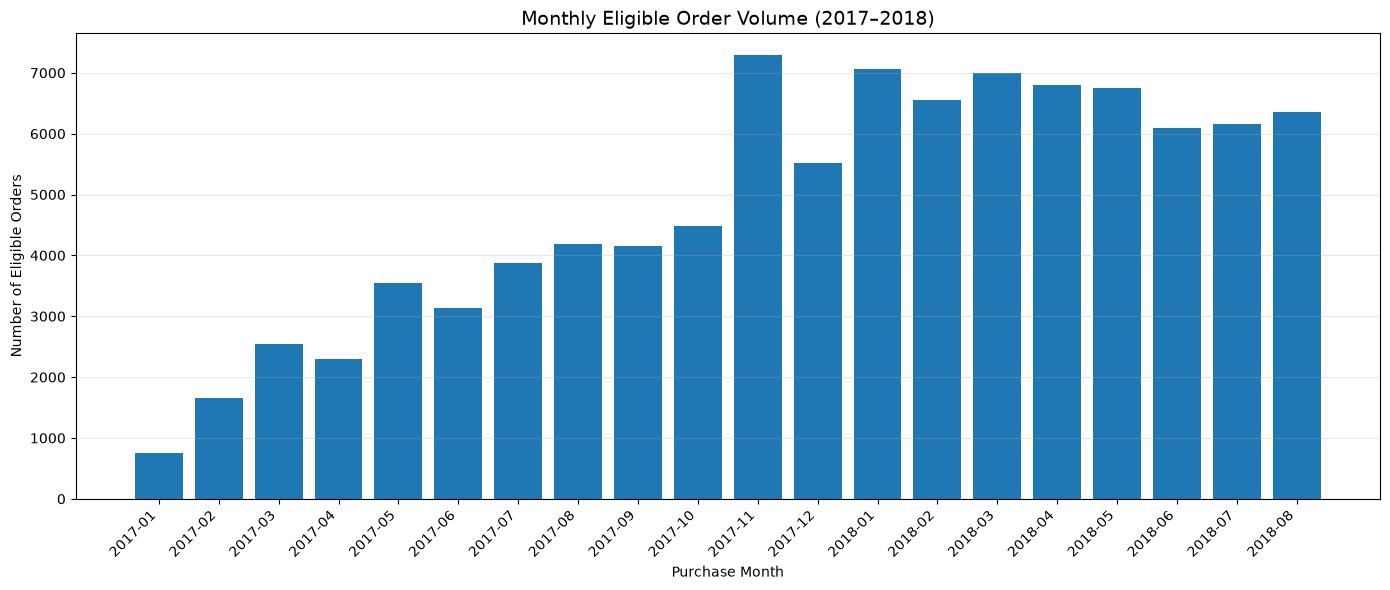

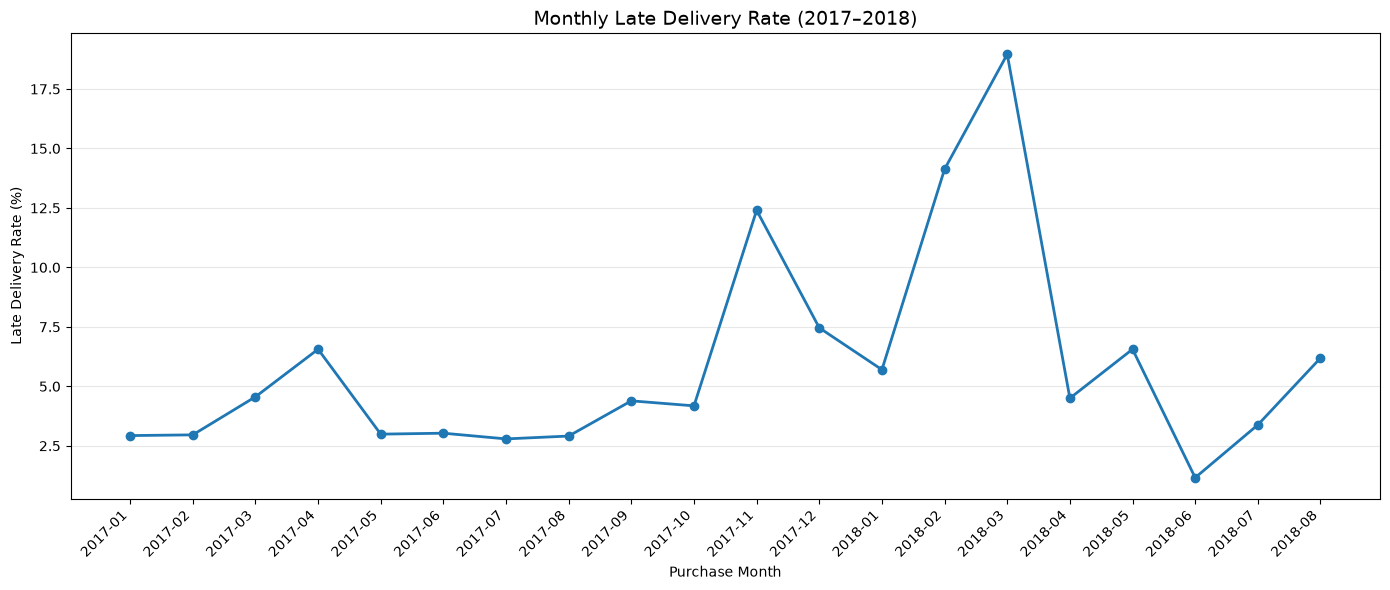


TOP 5 MONTHS WITH HIGHEST LATE DELIVERY RATES
purchase_month  total_orders  late_orders  late_rate_pct
       2018-03          7003         1328          18.96
       2018-02          6555          926          14.13
       2017-11          7288          904          12.40
       2017-12          5513          411           7.46
       2017-04          2303          151           6.56

TOP 5 MONTHS WITH LOWEST LATE DELIVERY RATES
purchase_month  total_orders  late_orders  late_rate_pct
       2018-06          6096           71           1.16
       2017-07          3872          108           2.79
       2017-08          4193          122           2.91
       2017-01           750           22           2.93
       2017-02          1653           49           2.96

Monthly visualization completed.


In [4]:
# =========================================================
# SECTION 4: MONTHLY DATA VISUALIZATION
# =========================================================

# Select the main visualization period
plot_data = monthly_stats[
    monthly_stats["purchase_month"].between(
        "2017-01", "2018-08"
    )
].copy()

# Validate visualization data
assert not plot_data.empty
assert (plot_data["total_orders"] > 0).all()

print("Visualization period:")
print(
    plot_data["purchase_month"].min(),
    "to",
    plot_data["purchase_month"].max()
)

print("Number of months:", len(plot_data))


# ---------------------------------------------------------
# CHART 1: MONTHLY ELIGIBLE ORDER VOLUME
# ---------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.bar(
    plot_data["purchase_month"],
    plot_data["total_orders"]
)

plt.title(
    "Monthly Eligible Order Volume (2017–2018)",
    fontsize=14
)

plt.xlabel("Purchase Month")
plt.ylabel("Number of Eligible Orders")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# CHART 2: MONTHLY LATE DELIVERY RATE
# ---------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["purchase_month"],
    plot_data["late_rate_pct"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Late Delivery Rate (2017–2018)",
    fontsize=14
)

plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# SUMMARY: HIGHEST AND LOWEST LATE DELIVERY RATES
# ---------------------------------------------------------

print("\nTOP 5 MONTHS WITH HIGHEST LATE DELIVERY RATES")

print(
    plot_data.nlargest(5, "late_rate_pct")[
        [
            "purchase_month",
            "total_orders",
            "late_orders",
            "late_rate_pct"
        ]
    ].to_string(index=False)
)

print("\nTOP 5 MONTHS WITH LOWEST LATE DELIVERY RATES")

print(
    plot_data.nsmallest(5, "late_rate_pct")[
        [
            "purchase_month",
            "total_orders",
            "late_orders",
            "late_rate_pct"
        ]
    ].to_string(index=False)
)

print("\nMonthly visualization completed.")

## 5. Confidence Interval Analysis

### Objective
Quantify the statistical uncertainty associated with
monthly late-delivery rates.

### Methodology
- Use the Wilson score confidence interval.
- Set the confidence level to 95%.
- Calculate lower and upper confidence bounds for each month.
- Visualize monthly rates with confidence intervals.

### Limitations
The Wilson interval assumes independent Bernoulli observations.
Orders may share sellers, customers, or time-related factors,
so these intervals are descriptive approximations.

Overlapping or non-overlapping monthly confidence intervals
alone do not establish seasonality or causal relationships.

In [5]:
# =========================================================
# SECTION 5: CONFIDENCE INTERVAL ANALYSIS
# =========================================================

# Wilson score confidence interval for a binomial proportion

z = 1.96  # Approximate 95% confidence level

ci_data = plot_data.copy()

n = ci_data["total_orders"].to_numpy(dtype=float)
x = ci_data["late_orders"].to_numpy(dtype=float)

p = x / n

# Wilson interval calculation
denominator = 1 + z**2 / n

center = (
    p + z**2 / (2 * n)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    )
)

# Convert intervals into percentages
ci_data["ci_lower"] = (center - margin) * 100
ci_data["ci_upper"] = (center + margin) * 100

ci_data["ci_lower"] = ci_data["ci_lower"].round(2)
ci_data["ci_upper"] = ci_data["ci_upper"].round(2)

# Display results
print("MONTHLY LATE DELIVERY RATE WITH 95% WILSON CI")

print(
    ci_data[
        [
            "purchase_month",
            "total_orders",
            "late_orders",
            "late_rate_pct",
            "ci_lower",
            "ci_upper"
        ]
    ].to_string(index=False)
)

# Validation
assert (n > 0).all()
assert (x >= 0).all()
assert (x <= n).all()

assert (
    ci_data["ci_lower"] <= ci_data["late_rate_pct"]
).all()

assert (
    ci_data["late_rate_pct"] <= ci_data["ci_upper"]
).all()

print("\nConfidence interval calculation passed.")

MONTHLY LATE DELIVERY RATE WITH 95% WILSON CI
purchase_month  total_orders  late_orders  late_rate_pct  ci_lower  ci_upper
       2017-01           750           22           2.93      1.94      4.40
       2017-02          1653           49           2.96      2.25      3.90
       2017-03          2546          116           4.56      3.81      5.44
       2017-04          2303          151           6.56      5.62      7.64
       2017-05          3545          106           2.99      2.48      3.60
       2017-06          3135           95           3.03      2.49      3.69
       2017-07          3872          108           2.79      2.32      3.36
       2017-08          4193          122           2.91      2.44      3.46
       2017-09          4150          182           4.39      3.80      5.05
       2017-10          4478          187           4.18      3.63      4.80
       2017-11          7288          904          12.40     11.67     13.18
       2017-12          5513  

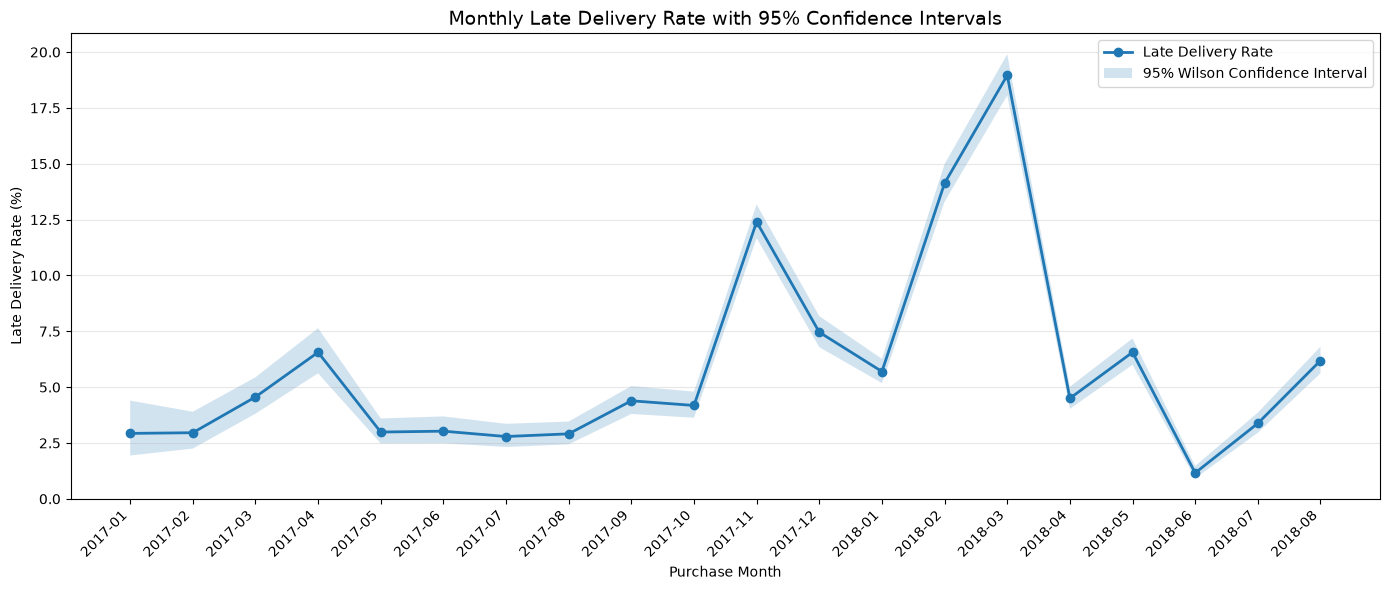

Confidence interval visualization completed.


In [6]:
# =========================================================
# SECTION 5: MONTHLY RATE WITH 95% CONFIDENCE INTERVAL
# =========================================================

months = ci_data["purchase_month"].tolist()
positions = np.arange(len(months))

rates = ci_data["late_rate_pct"].to_numpy()
lower = ci_data["ci_lower"].to_numpy()
upper = ci_data["ci_upper"].to_numpy()

plt.figure(figsize=(14, 6))

# Monthly late-delivery rate
plt.plot(
    positions,
    rates,
    marker="o",
    linewidth=2,
    label="Late Delivery Rate"
)

# Confidence interval band
plt.fill_between(
    positions,
    lower,
    upper,
    alpha=0.2,
    label="95% Wilson Confidence Interval"
)

plt.title(
    "Monthly Late Delivery Rate with 95% Confidence Intervals",
    fontsize=14
)

plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(
    positions,
    months,
    rotation=45,
    ha="right"
)

plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

print("Confidence interval visualization completed.")

## 6. Statistical Interpretation and Limitations

### 6.1. Monthly Order Volume

The number of eligible orders generally increased throughout
2017. November 2017 recorded the highest eligible order
volume in the selected analysis period, with 7,288 orders.

During 2018, monthly eligible order volumes remained
relatively high, generally exceeding 6,000 orders.

These observations describe the historical dataset and
should not be interpreted as evidence of overall market growth.

### 6.2. Monthly Late Delivery Patterns

Monthly late-delivery rates varied considerably between
January 2017 and August 2018.

March 2018 recorded the highest observed late-delivery
rate at 18.96% (1,328 out of 7,003 eligible orders).

Other notable months included February 2018 (14.13%)
and November 2017 (12.40%).

The lowest rate occurred in June 2018, at 1.16%
(71 out of 6,096 eligible orders).

The rate decreased from 18.96% in March 2018 to 4.50%
in April 2018, representing a decline of 14.46
percentage points.

These changes indicate temporal variation but do not
establish its underlying causes.

### 6.3. Confidence Interval Interpretation

The 95% Wilson confidence interval for March 2018
was [18.06%, 19.90%].

For June 2018, the corresponding interval was
[0.92%, 1.47%].

Confidence intervals provide an indication of uncertainty
under the assumed binomial model.

They should not be interpreted as direct evidence of
causality, seasonality, or statistically significant
differences between months.

### 6.4. Data Completeness

The main visualizations cover January 2017 to August 2018.

Sparse months in 2016 were excluded from the main charts
but retained in the data completeness assessment.

September and October 2018 contained no valid
late-delivery labels.

Orders without valid labels were excluded from the
late-delivery rate denominator.

The availability of valid labels and incomplete observation
periods may affect the interpretation of monthly patterns.

### 6.5. Statistical Limitations

Several limitations should be considered:

1. The dataset covers historical transactions from 2016–2018.
2. The Olist dataset is not a random representative sample
   of all Brazilian e-commerce transactions.
3. Orders may be statistically dependent through common
   sellers, customers, or time-related factors.
4. The Wilson intervals assume independent Bernoulli
   observations and are therefore approximate.
5. Excluding orders with missing delivery labels may
   introduce selection bias.
6. Observed monthly differences do not establish
   causality or seasonality.

### 6.6. Preliminary Conclusion

The analysis identifies substantial variation in
late-delivery rates across purchase months.

Particularly high rates were observed in November 2017,
February 2018, and March 2018.

These findings provide descriptive evidence of temporal
patterns and motivate further investigation.

However, additional statistical analysis and appropriate
predictive model evaluation are necessary before drawing
conclusions about underlying mechanisms or predictive value.

## 7. Export Analysis Results

### Objective
Export the statistical results and visualizations
for reproducibility and integration into the final
project report.

### Output Files
- Monthly late-delivery statistics
- Monthly data completeness summary
- Monthly late-delivery rates with 95% Wilson confidence intervals
- Publication-ready figures

In [7]:
# =========================================================
# SECTION 7.1: EXPORT STATISTICAL TABLES
# =========================================================

# Create output directory
tables_dir = ROOT / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# TABLE 1: MONTHLY LATE DELIVERY STATISTICS
# ---------------------------------------------------------

monthly_stats.to_csv(
    tables_dir / "monthly_late_delivery_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

# ---------------------------------------------------------
# TABLE 2: MONTHLY DATA COMPLETENESS
# ---------------------------------------------------------

monthly_completeness.to_csv(
    tables_dir / "monthly_data_completeness.csv",
    index=False,
    encoding="utf-8-sig"
)

# ---------------------------------------------------------
# TABLE 3: MONTHLY WILSON CONFIDENCE INTERVALS
# ---------------------------------------------------------

ci_data.to_csv(
    tables_dir / "monthly_late_delivery_wilson_ci.csv",
    index=False,
    encoding="utf-8-sig"
)

# ---------------------------------------------------------
# VERIFY EXPORTED FILES
# ---------------------------------------------------------

print("EXPORTED STATISTICAL TABLES\n")

for file_path in sorted(tables_dir.glob("*.csv")):
    exported_data = pd.read_csv(file_path)

    print(f"File: {file_path.name}")
    print(f"Rows: {len(exported_data)}")
    print(f"Columns: {len(exported_data.columns)}")
    print(f"Size: {file_path.stat().st_size:,} bytes")
    print("-" * 45)

print("\nStatistical tables exported successfully.")

EXPORTED STATISTICAL TABLES

File: monthly_data_completeness.csv
Rows: 25
Columns: 7
Size: 1,767 bytes
---------------------------------------------
File: monthly_late_delivery_statistics.csv
Rows: 23
Columns: 4
Size: 570 bytes
---------------------------------------------
File: monthly_late_delivery_wilson_ci.csv
Rows: 20
Columns: 6
Size: 730 bytes
---------------------------------------------

Statistical tables exported successfully.


### 7.2. Export Statistical Figures

Three figures are exported as high-resolution PNG files
at 300 DPI for use in the final report and IEEE paper.

1. Monthly Eligible Order Volume
2. Monthly Late Delivery Rate
3. Monthly Late Delivery Rate with 95% Wilson Confidence Intervals

All figures cover January 2017 to August 2018.

In [8]:
# =========================================================
# SECTION 7.2: EXPORT STATISTICAL FIGURES
# =========================================================

# Create figures directory
figures_dir = ROOT / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

months = plot_data["purchase_month"].tolist()
positions = np.arange(len(months))


# ---------------------------------------------------------
# FIGURE 1: MONTHLY ELIGIBLE ORDER VOLUME
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    positions,
    plot_data["total_orders"]
)

ax.set_title(
    "Monthly Eligible Order Volume (2017–2018)",
    fontsize=14
)

ax.set_xlabel("Purchase Month")
ax.set_ylabel("Number of Eligible Orders")

ax.set_xticks(positions)
ax.set_xticklabels(months, rotation=45, ha="right")

ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    figures_dir / "monthly_eligible_order_volume.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close(fig)


# ---------------------------------------------------------
# FIGURE 2: MONTHLY LATE DELIVERY RATE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    positions,
    plot_data["late_rate_pct"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Late Delivery Rate (2017–2018)",
    fontsize=14
)

ax.set_xlabel("Purchase Month")
ax.set_ylabel("Late Delivery Rate (%)")

ax.set_xticks(positions)
ax.set_xticklabels(months, rotation=45, ha="right")

ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    figures_dir / "monthly_late_delivery_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close(fig)


# ---------------------------------------------------------
# FIGURE 3: MONTHLY LATE DELIVERY RATE WITH 95% CI
# ---------------------------------------------------------

ci_months = ci_data["purchase_month"].tolist()
ci_positions = np.arange(len(ci_months))

rates = ci_data["late_rate_pct"].to_numpy()
lower = ci_data["ci_lower"].to_numpy()
upper = ci_data["ci_upper"].to_numpy()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    ci_positions,
    rates,
    marker="o",
    linewidth=2,
    label="Late Delivery Rate"
)

ax.fill_between(
    ci_positions,
    lower,
    upper,
    alpha=0.2,
    label="95% Wilson Confidence Interval"
)

ax.set_title(
    "Monthly Late Delivery Rate with 95% Confidence Intervals",
    fontsize=14
)

ax.set_xlabel("Purchase Month")
ax.set_ylabel("Late Delivery Rate (%)")

ax.set_xticks(ci_positions)
ax.set_xticklabels(ci_months, rotation=45, ha="right")

ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figures_dir / "monthly_late_delivery_wilson_ci.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close(fig)


# ---------------------------------------------------------
# VERIFY EXPORTED FIGURES
# ---------------------------------------------------------

expected_files = [
    "monthly_eligible_order_volume.png",
    "monthly_late_delivery_rate.png",
    "monthly_late_delivery_wilson_ci.png"
]

print("EXPORTED STATISTICAL FIGURES\n")

for filename in expected_files:
    file_path = figures_dir / filename

    assert file_path.exists(), f"Missing file: {filename}"
    assert file_path.stat().st_size > 0, f"Empty file: {filename}"

    print(f"File: {filename}")
    print(f"Size: {file_path.stat().st_size:,} bytes")
    print("-" * 45)

print("\nAll statistical figures exported successfully.")

EXPORTED STATISTICAL FIGURES

File: monthly_eligible_order_volume.png
Size: 132,693 bytes
---------------------------------------------
File: monthly_late_delivery_rate.png
Size: 262,357 bytes
---------------------------------------------
File: monthly_late_delivery_wilson_ci.png
Size: 352,269 bytes
---------------------------------------------

All statistical figures exported successfully.
